In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:

import copy                      # to keep a copy of the best model weights during training
import random                    # shuffling data and picking random images
import time                      # measuring how long things take
import shutil                    # copying folders
from pathlib import Path         # easier file paths than plain strings

import numpy as np               # numbers and arrays (used for the confusion matrix)
import matplotlib.pyplot as plt  # drawing plots
from PIL import Image            # opening image files
from tqdm.auto import tqdm       # progress bars (training can take a while)

import torch                                      # PyTorch, the deep learning library
from torch import nn, optim                       # nn = layers and loss functions, optim = optimizers
from torch.utils.data import DataLoader, Subset   # DataLoader serves batches, Subset picks part of a dataset
from torchvision import datasets, transforms, models  # image folders, image preprocessing, pretrained models

# Use the GPU if Colab gave us one, otherwise the CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Device:", device)

if device.type == "cpu":
    print("\nNo GPU found. Training will be slow, so quick-test mode will be switched on below.")
    print("For a GPU: Runtime > Change runtime type > T4 GPU")

PyTorch version: 2.14.1+cpu
Device: cpu

No GPU found. Training will be slow, so quick-test mode will be switched on below.
For a GPU: Runtime > Change runtime type > T4 GPU


In [24]:
# --- Where the data is -------------------------------------------------------
# Pointing to the newly extracted folder in our local Colab disk
DATA_ROOT = Path("/content/ct_scans/Preprocessed CT scans")

# Where the trained model will be saved (on Drive, so it survives after the session ends)
SAVE_PATH = Path("/content/drive/MyDrive/ct_classifier.pth")

# --- Quick-test mode ---------------------------------------------------------
QUICK_TEST = (device.type == "cpu")      # True when there is no GPU. Edit to True/False to override.

# --- Training settings -------------------------------------------------------
IMG_SIZE        = 224    # the network takes 224 x 224 pixel images
BATCH_SIZE      = 32     # images processed together before each weight update
LEARNING_RATE   = 1e-4   # size of each weight update (0.0001, small because the model is pretrained)
SEED            = 42     # makes shuffling repeatable

if QUICK_TEST:
    EPOCHS               = 100    # one epoch = one pass over all training images
    MAX_IMAGES_PER_CLASS = 300   # use only this many images from each class
    FREEZE_BACKBONE      = True  # only train the new final layers (faster)
    COPY_TO_LOCAL        = False # only ~900 images are read, so reading from Drive is OK
else:
    EPOCHS               = 100
    MAX_IMAGES_PER_CLASS = None  # None = use every image
    FREEZE_BACKBONE      = False # fine-tune the whole network
    COPY_TO_LOCAL        = True  # reading 20k images from Drive every epoch is slow, copy them first

# Make random numbers repeatable (same shuffle and same starting weights each run)
random.seed(SEED)
torch.manual_seed(SEED)

print(f"Quick test: {QUICK_TEST} | epochs: {EPOCHS} | images per class: {MAX_IMAGES_PER_CLASS or 'all'} "
      f"| freeze backbone: {FREEZE_BACKBONE}")

Quick test: True | epochs: 100 | images per class: 300 | freeze backbone: True


In [25]:
if COPY_TO_LOCAL:
    local_copy = Path("/content/ct_scans")
    if not local_copy.exists():                 # don't copy twice if you re-run the cell
        print("Copying images from Drive, this can take several minutes...")
        shutil.copytree(DATA_ROOT, local_copy)
    DATA_ROOT = local_copy                      # from now on, read from the fast local copy

print("Reading images from:", DATA_ROOT)

Reading images from: /content/ct_scans/Preprocessed CT scans


In [26]:
import zipfile
from pathlib import Path

# Search for archive.zip in Drive
drive_root = Path('/content/drive/MyDrive')
zip_paths = list(drive_root.rglob('archive.zip'))

if not zip_paths:
    print("Could not find 'archive.zip' in Google Drive. Please make sure it is uploaded directly to your My Drive or a subfolder.")
else:
    zip_path = zip_paths[0]
    print(f"Found archive at: {zip_path}")

    # Destination folder for extraction
    extract_to = Path('/content/ct_scans')
    extract_to.mkdir(exist_ok=True)

    print("Extracting archive... this may take a moment.")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_to)

    print(f"Successfully extracted to: {extract_to}")
    # Update DATA_ROOT to point to the extracted folder structure
    # Usually archives extract to a subfolder, so let's verify what folders were extracted:
    extracted_items = list(extract_to.glob('*'))
    print("Extracted items:", [f.name for f in extracted_items if f.is_dir()])

Found archive at: /content/drive/MyDrive/archive.zip
Extracting archive... this may take a moment.
Successfully extracted to: /content/ct_scans
Extracted items: ['Original CT Scans', 'Preprocessed CT scans']


In [27]:
# Average and spread of the red, green and blue values in ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),                       # make the shorter side 256 pixels
    transforms.RandomResizedCrop(IMG_SIZE),       # random piece of the image, resized to 224 x 224
    transforms.RandomHorizontalFlip(),            # mirror left-right half of the time
    transforms.ToTensor(),                        # image -> tensor of shape [3, 224, 224], values 0 to 1
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # (pixel - mean) / std for each colour channel
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),              # always the middle 224 x 224 part
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [28]:
train_dataset = datasets.ImageFolder(DATA_ROOT, transform=train_transform)
eval_dataset  = datasets.ImageFolder(DATA_ROOT, transform=eval_transform)

class_names = train_dataset.classes     # e.g. ['NiCT', 'nCT', 'pCT']
num_classes = len(class_names)

# Safety check: we expect exactly these three folders
expected = {"nCT", "NiCT", "pCT"}
if set(class_names) != expected:
    raise ValueError(f"Expected folders {sorted(expected)} but found {class_names}. "
                     f"Check DATA_ROOT, and remove any extra folders.")

print("Classes:", class_names)
print("Total images:", len(train_dataset))

Classes: ['NiCT', 'nCT', 'pCT']
Total images: 19685


NiCT   5,705 images
nCT    9,979 images
pCT    4,001 images


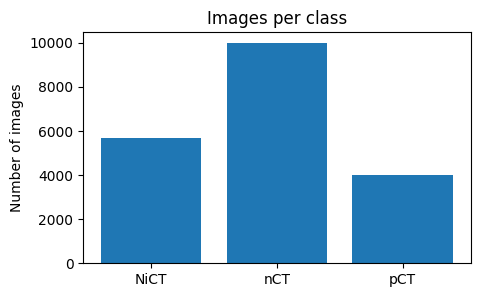

In [29]:
# train_dataset.samples is a list of (file_path, class_number) pairs
all_labels = [label for _, label in train_dataset.samples]
counts = [all_labels.count(i) for i in range(num_classes)]

for name, count in zip(class_names, counts):
    print(f"{name:5s} {count:6,} images")

plt.figure(figsize=(5, 3))
plt.bar(class_names, counts)
plt.ylabel("Number of images")
plt.title("Images per class")
plt.show()

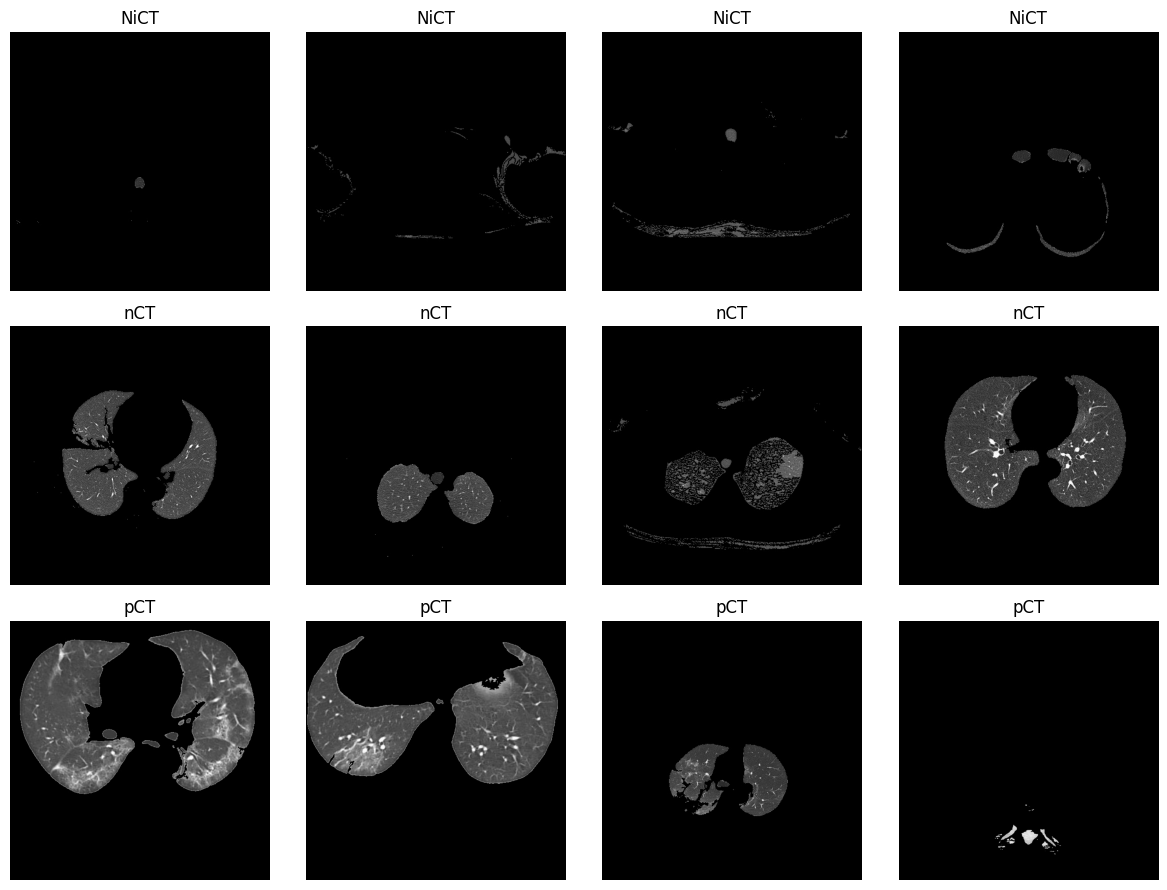

In [30]:
images_per_row = 4
fig, axes = plt.subplots(num_classes, images_per_row, figsize=(12, 3 * num_classes))

for row, name in enumerate(class_names):
    # all file paths that belong to this class
    class_paths = [path for path, label in train_dataset.samples if label == row]
    for col, path in enumerate(random.sample(class_paths, images_per_row)):
        axes[row, col].imshow(Image.open(path).convert("RGB"))
        axes[row, col].set_title(name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [31]:
def split_indices(dataset, train_frac=0.70, val_frac=0.15, max_per_class=None, seed=42):
    # Returns three lists of image indices: train, validation, test.
    rng = random.Random(seed)
    train_idx, val_idx, test_idx = [], [], []

    for class_number in range(num_classes):
        # Indices of all images of this class
        class_idx = [i for i, (_, label) in enumerate(dataset.samples) if label == class_number]

        rng.shuffle(class_idx)                 # random order
        if max_per_class is not None:          # quick-test mode: keep only a few
            class_idx = class_idx[:max_per_class]

        n_train = int(train_frac * len(class_idx))
        n_val   = int(val_frac * len(class_idx))

        train_idx += class_idx[:n_train]                    # first 70%
        val_idx   += class_idx[n_train:n_train + n_val]     # next 15%
        test_idx  += class_idx[n_train + n_val:]            # remaining 15%

    return train_idx, val_idx, test_idx


train_idx, val_idx, test_idx = split_indices(train_dataset, max_per_class=MAX_IMAGES_PER_CLASS, seed=SEED)
print(f"Train: {len(train_idx):,} | Validation: {len(val_idx):,} | Test: {len(test_idx):,}")

Train: 630 | Validation: 135 | Test: 135


In [32]:
train_loader = DataLoader(Subset(train_dataset, train_idx), batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(Subset(eval_dataset,  val_idx),   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(Subset(eval_dataset,  test_idx),  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Look at one batch to check the shapes
images, labels = next(iter(train_loader))
print("Images in a batch:", images.shape)   # [batch, 3 colour channels, 224 height, 224 width]
print("Labels in a batch:", labels.shape)   # one class number per image

Images in a batch: torch.Size([32, 3, 224, 224])
Labels in a batch: torch.Size([32])


In [33]:
def build_model(num_classes, freeze_backbone=False, pretrained=True):
    # Start from MobileNetV3-Large (with ImageNet knowledge, unless pretrained=False)
    weights = "DEFAULT" if pretrained else None
    model = models.mobilenet_v3_large(weights=weights)

    # Optionally lock the backbone so only the new classifier learns
    if freeze_backbone:
        for param in model.features.parameters():
            param.requires_grad = False

    # Replace the final layers with our own 3-class classifier
    model.classifier = nn.Sequential(
        nn.Linear(960, 1280),
        nn.ReLU(),
        nn.Dropout(p=0.2),
        nn.Linear(1280, num_classes),
    )
    return model


model = build_model(num_classes, freeze_backbone=FREEZE_BACKBONE)
model = model.to(device)    # move the weights to the GPU (or keep on CPU)

# Count how many numbers the model is allowed to change during training
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {trainable:,} of {total:,}")

Trainable parameters: 1,233,923 of 4,205,875


In [34]:
import sys
from unittest.mock import MagicMock

# Stub out torch._dynamo entirely in sys.modules before importing optimizer
# to prevent the circular dependency check from crashing during optimization instantiation
if 'torch._dynamo' not in sys.modules:
    sys.modules['torch._dynamo'] = MagicMock()

import torch
import torch.optim as optim

loss_function = nn.CrossEntropyLoss()

trainable_params = [p for p in model.parameters() if p.requires_grad]
optimizer = optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=1e-4)

In [35]:
def evaluate(model, loader):
    # Returns (average loss, accuracy) of the model on this loader. No learning happens here.
    model.eval()                          # evaluation mode (Dropout off)
    total_loss, correct, seen = 0.0, 0, 0

    with torch.no_grad():                 # we are not training, so no gradients needed
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)

            scores = model(images)                       # shape [batch, 3]: one score per class
            loss = loss_function(scores, labels)

            predictions = scores.argmax(dim=1)           # class with the highest score
            correct += (predictions == labels).sum().item()
            total_loss += loss.item() * labels.size(0)   # loss.item() is a batch average, so multiply back
            seen += labels.size(0)

    return total_loss / seen, correct / seen


def train_one_epoch(model, loader, optimizer):
    # Trains for one pass over the data. Returns (average loss, accuracy) on the training batches.
    model.train()                         # training mode (Dropout on)
    total_loss, correct, seen = 0.0, 0, 0

    for images, labels in tqdm(loader, desc="  training", leave=False):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()                      # 0. clear old gradients
        scores = model(images)                     # 1. forward pass
        loss = loss_function(scores, labels)       # 2. how wrong are we?
        loss.backward()                            # 3. backward pass: compute gradients
        optimizer.step()                           # 4. update the weights

        correct += (scores.argmax(dim=1) == labels).sum().item()
        total_loss += loss.item() * labels.size(0)
        seen += labels.size(0)

    return total_loss / seen, correct / seen

In [36]:
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_acc = 0.0
best_weights = copy.deepcopy(model.state_dict())   # a copy of the weights from the best epoch so far
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer)
    val_loss,   val_acc   = evaluate(model, val_loader)

    # Record this epoch's numbers for the plots
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Keep the weights if this is the best epoch so far
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model.state_dict())

    minutes = (time.time() - start_time) / 60
    print(f"Epoch {epoch}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.4f} "
          f"| val loss {val_loss:.4f}, acc {val_acc:.4f} | {minutes:.1f} min")

# Go back to the best weights
model.load_state_dict(best_weights)
print(f"\nDone. Best validation accuracy: {best_val_acc:.4f}")

  training:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1/100 | train loss 0.9723, acc 0.5603 | val loss 0.9330, acc 0.7630 | 0.9 min


  training:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 2/100 | train loss 0.7480, acc 0.7683 | val loss 0.8131, acc 0.8222 | 1.8 min


  training:   0%|          | 0/20 [00:00<?, ?it/s]

Epoch 3/100 | train loss 0.6128, acc 0.8016 | val loss 0.7065, acc 0.8370 | 2.7 min


... (208 outputs left out)

Epoch 99/100 | train loss 0.2503, acc 0.9048 | val loss 0.2377, acc 0.9111 | 91.7 min


  training:   0%|          | 0/20 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b22b80f1da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b22b80f1da0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 100/100 | train loss 0.3000, acc 0.8667 | val loss 0.2792, acc 0.8889 | 92.7 min

Done. Best validation accuracy: 0.9259


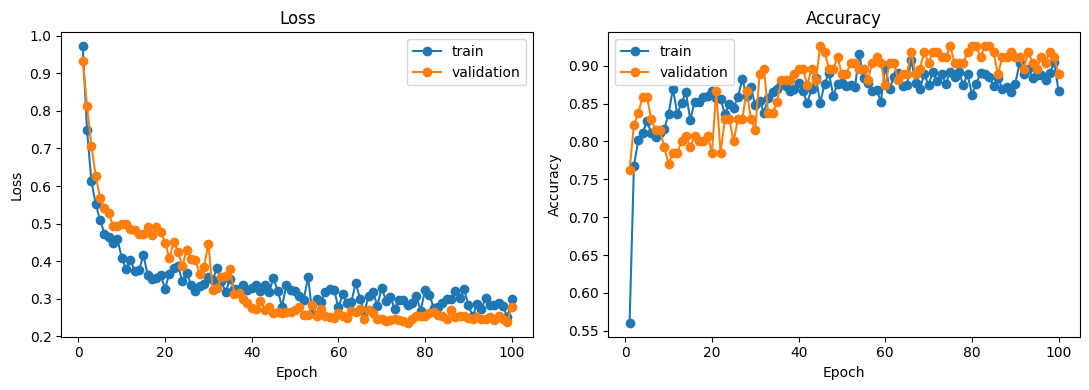

In [37]:
epochs_axis = range(1, len(history["train_loss"]) + 1)

fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 4))

ax_loss.plot(epochs_axis, history["train_loss"], marker="o", label="train")
ax_loss.plot(epochs_axis, history["val_loss"],   marker="o", label="validation")
ax_loss.set_xlabel("Epoch"); ax_loss.set_ylabel("Loss"); ax_loss.set_title("Loss"); ax_loss.legend()

ax_acc.plot(epochs_axis, history["train_acc"], marker="o", label="train")
ax_acc.plot(epochs_axis, history["val_acc"],   marker="o", label="validation")
ax_acc.set_xlabel("Epoch"); ax_acc.set_ylabel("Accuracy"); ax_acc.set_title("Accuracy"); ax_acc.legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = evaluate(model, test_loader)
print(f"Test accuracy: {test_acc * 100:.2f}%   (loss {test_loss:.4f})")

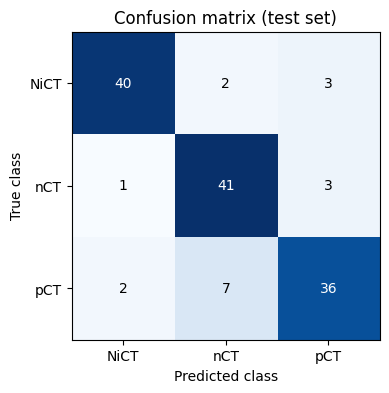

class   precision   recall
NiCT       93.02%   88.89%
nCT        82.00%   91.11%
pCT        85.71%   80.00%


In [39]:
# Collect the model's prediction for every test image
all_true, all_pred = [], []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        scores = model(images.to(device))
        all_pred += scores.argmax(dim=1).cpu().tolist()   # .cpu() moves results off the GPU
        all_true += labels.tolist()

# Build the confusion matrix: matrix[true, predicted] = how many images
matrix = np.zeros((num_classes, num_classes), dtype=int)
for true_label, predicted_label in zip(all_true, all_pred):
    matrix[true_label, predicted_label] += 1

# Draw it
plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")
plt.xticks(range(num_classes), class_names)
plt.yticks(range(num_classes), class_names)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("Confusion matrix (test set)")
for row in range(num_classes):
    for col in range(num_classes):
        text_color = "white" if matrix[row, col] > matrix.max() / 2 else "black"
        plt.text(col, row, matrix[row, col], ha="center", va="center", color=text_color)
plt.show()

# Precision and recall for each class
print(f"{'class':6s} {'precision':>10s} {'recall':>8s}")
for i, name in enumerate(class_names):
    precision = matrix[i, i] / max(matrix[:, i].sum(), 1)   # max(...,1) avoids dividing by zero
    recall    = matrix[i, i] / max(matrix[i, :].sum(), 1)
    print(f"{name:6s} {precision:10.2%} {recall:8.2%}")

In [ ]:
checkpoint = {
    "state_dict": model.state_dict(),   # all learned weights
    "class_names": class_names,         # e.g. ['NiCT', 'nCT', 'pCT']
    "img_size": IMG_SIZE,
}
torch.save(checkpoint, SAVE_PATH)
print("Saved to", SAVE_PATH)

In [41]:
checkpoint = torch.load(SAVE_PATH, map_location=device)

model = build_model(len(checkpoint["class_names"]), pretrained=False)
model.load_state_dict(checkpoint["state_dict"])
model = model.to(device)
model.eval()
print("Model loaded. Classes:", checkpoint["class_names"])

Model loaded. Classes: ['NiCT', 'nCT', 'pCT']


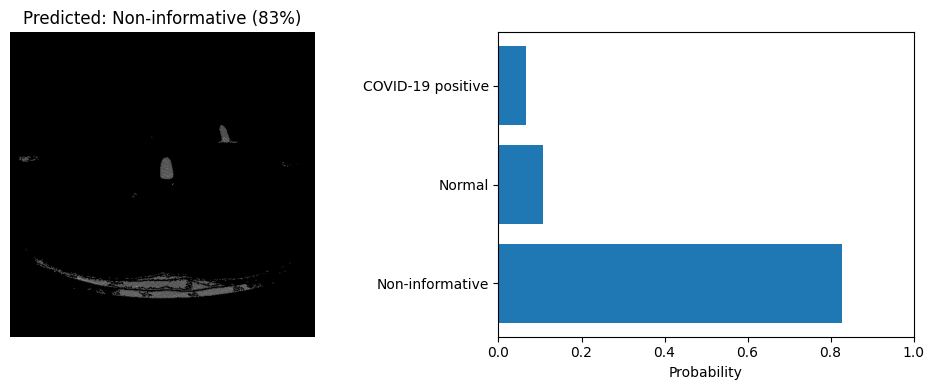

True class: Non-informative


In [42]:
readable_names = {"nCT": "Normal", "pCT": "COVID-19 positive", "NiCT": "Non-informative"}

def show_prediction(image_path):
    image = Image.open(image_path).convert("RGB")   # CT slices may be grayscale; the model expects 3 channels

    # Preprocess exactly like validation images, then add a batch dimension: [3,224,224] -> [1,3,224,224]
    x = eval_transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        probabilities = torch.softmax(model(x), dim=1)[0].cpu().numpy()   # [0] = first (only) image

    best = probabilities.argmax()
    labels = [readable_names[name] for name in class_names]

    fig, (ax_image, ax_bars) = plt.subplots(1, 2, figsize=(10, 4))
    ax_image.imshow(image)
    ax_image.axis("off")
    ax_image.set_title(f"Predicted: {labels[best]} ({probabilities[best]:.0%})")
    ax_bars.barh(labels, probabilities)
    ax_bars.set_xlim(0, 1)
    ax_bars.set_xlabel("Probability")
    plt.tight_layout()
    plt.show()

# Try a random test image and compare with the truth
path, true_label = eval_dataset.samples[random.choice(test_idx)]
show_prediction(path)
print("True class:", readable_names[class_names[true_label]])